<a href="https://colab.research.google.com/github/ancestor9/Scikit-learn-model-selection-evaluation/blob/main/exercise/imbalanced_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

0번 클래스: 985개, 1번 클래스(소수): 15개
테스트 AUROC: 0.7388 | AP: 0.1881


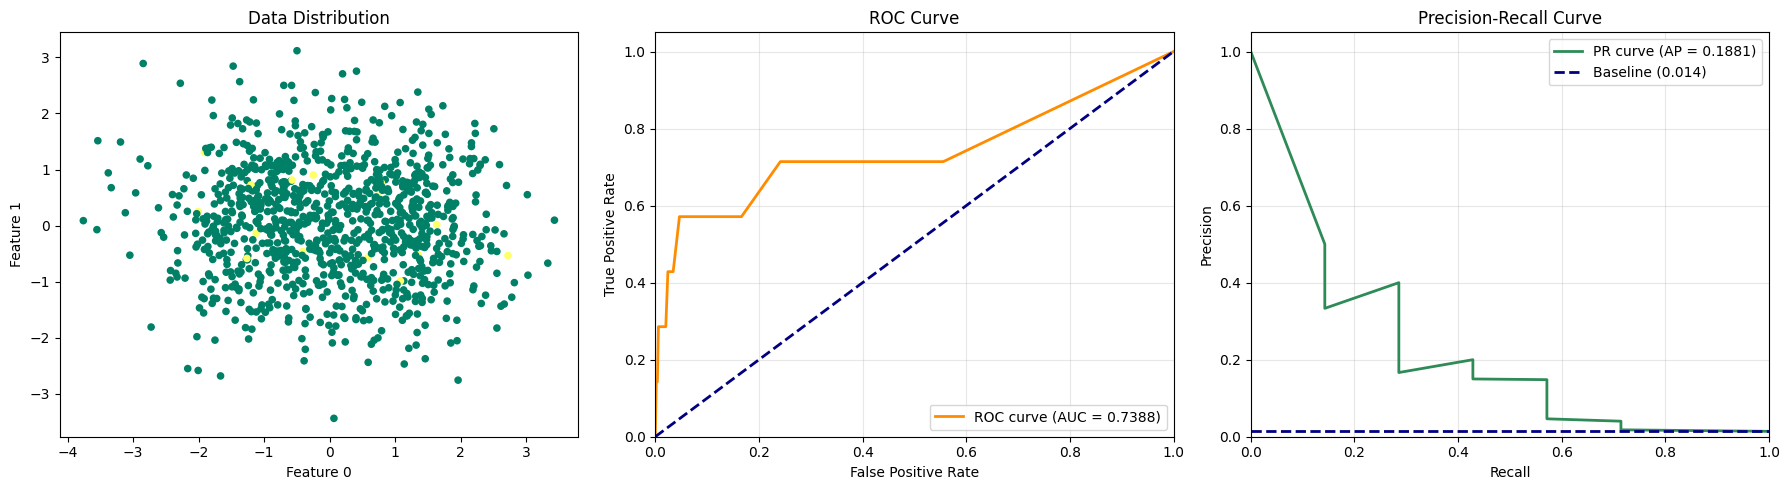

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score

# 1. 데이터 생성 (소수 클래스 약 1%)
X, y = make_classification(n_samples=1000, weights=[0.99, 0.01], random_state=1)
print(f"0번 클래스: {np.bincount(y)[0]}개, 1번 클래스(소수): {np.bincount(y)[1]}개")

# 2. 층화 분할 + 학습
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, stratify=y, random_state=42)
model = RandomForestClassifier(random_state=42).fit(X_train, y_train)

# 3. 소수 클래스 확률로 AUROC, AP 계산
proba = model.predict_proba(X_test)[:, 1]
auroc = roc_auc_score(y_test, proba)
ap = average_precision_score(y_test, proba)
fpr, tpr, _ = roc_curve(y_test, proba)
precision, recall, _ = precision_recall_curve(y_test, proba)
print(f"테스트 AUROC: {auroc:.4f} | AP: {ap:.4f}")

# 4. 시각화 (1행 3열)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

ax1.scatter(X[:, 0], X[:, 1], c=y, s=20, cmap='summer')
ax1.set(title='Data Distribution', xlabel='Feature 0', ylabel='Feature 1')

ax2.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auroc:.4f})')
ax2.plot([0, 1], [0, 1], color='navy', lw=2, ls='--')
ax2.set(title='ROC Curve', xlabel='False Positive Rate', ylabel='True Positive Rate',
        xlim=(0, 1), ylim=(0, 1.05))
ax2.legend(loc='lower right')
ax2.grid(alpha=0.3)

ax3.plot(recall, precision, color='seagreen', lw=2, label=f'PR curve (AP = {ap:.4f})')
ax3.axhline(y_test.mean(), color='navy', lw=2, ls='--', label=f'Baseline ({y_test.mean():.3f})')
ax3.set(title='Precision-Recall Curve', xlabel='Recall', ylabel='Precision',
        xlim=(0, 1), ylim=(0, 1.05))
ax3.legend(loc='upper right')
ax3.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
import pandas as pd
from sklearn.metrics import confusion_matrix, roc_curve

# 1. roc_curve에서 나온 동일한 길이의 tpr, fpr, thresholds 사용
fpr_val, tpr_val, thresholds_val = roc_curve(y_test, proba)

# 무한대(inf)로 정의된 첫 임계값 처리 (scikit-learn의 roc_curve는 임계값의 최댓값보다 큰 값을 첫 원소로 반환함)
thresholds_clean = np.where(np.isinf(thresholds_val), 1.0, thresholds_val)

def counts(t):
    return confusion_matrix(y_test, (proba >= t).astype(int), labels=[0, 1]).ravel()

threshold_df = pd.DataFrame(
    [counts(t) for t in thresholds_clean], columns=['TN', 'FP', 'FN', 'TP']
).assign(**{
    'Threshold': thresholds_clean,
    'TPR (Recall)': tpr_val,
    'FPR': fpr_val
})

threshold_df = threshold_df[['Threshold', 'TPR (Recall)', 'FPR', 'TN', 'FP', 'FN', 'TP']]
threshold_df

,Threshold,TPR (Recall),FPR,TN,FP,FN,TP
0,1.00,0.000000,0.000000,493,0,7,0
1,0.21,0.142857,0.002028,492,1,6,1
2,0.18,0.142857,0.004057,491,2,6,1
3,0.17,0.285714,0.006085,490,3,5,2
4,0.14,0.285714,0.012170,487,6,5,2
5,0.12,0.285714,0.014199,486,7,5,2
6,0.11,0.285714,0.020284,483,10,5,2
7,0.10,0.428571,0.024341,481,12,4,3
8,0.09,0.428571,0.034483,476,17,4,3
9,0.08,0.571429,0.046653,470,23,3,4


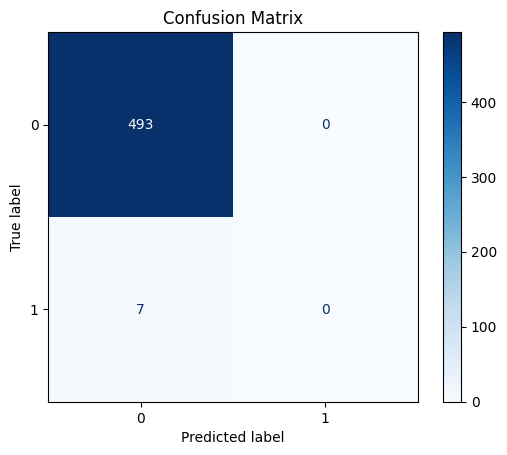

              precision    recall  f1-score   support

           0       0.99      1.00      0.99       493
           1       0.00      0.00      0.00         7

    accuracy                           0.99       500
   macro avg       0.49      0.50      0.50       500
weighted avg       0.97      0.99      0.98       500



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt

# Confusion Matrix 계산
y_pred = (proba >= 0.5).astype(int)
cm = confusion_matrix(y_test, y_pred)

# Confusion Matrix 시각화
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

print(classification_report(y_test, y_pred))

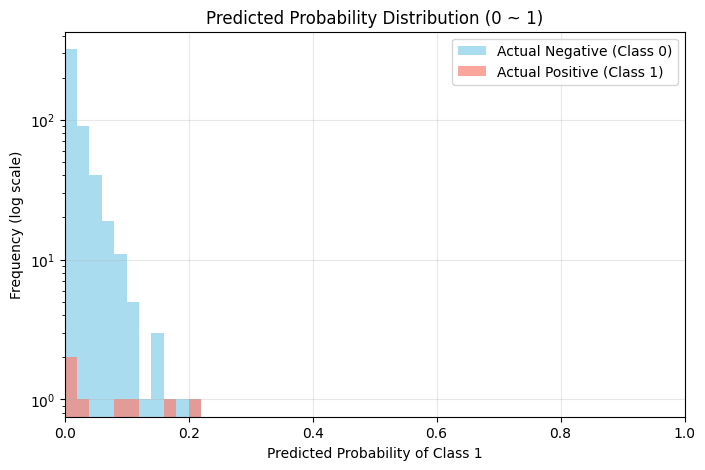

In [13]:
bins = np.linspace(0, 1, 51)  # 0~1 구간을 50개로 균등 분할

plt.figure(figsize=(8, 5))
plt.hist(proba[y_test == 0], bins=bins, alpha=0.7, color='skyblue', label='Actual Negative (Class 0)')
plt.hist(proba[y_test == 1], bins=bins, alpha=0.7, color='salmon', label='Actual Positive (Class 1)')

plt.xlim(0, 1)
plt.yscale('log')  # 클래스 불균형 때문에 양성 막대가 보이도록 로그 스케일
plt.title('Predicted Probability Distribution (0 ~ 1)')
plt.xlabel('Predicted Probability of Class 1')
plt.ylabel('Frequency (log scale)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

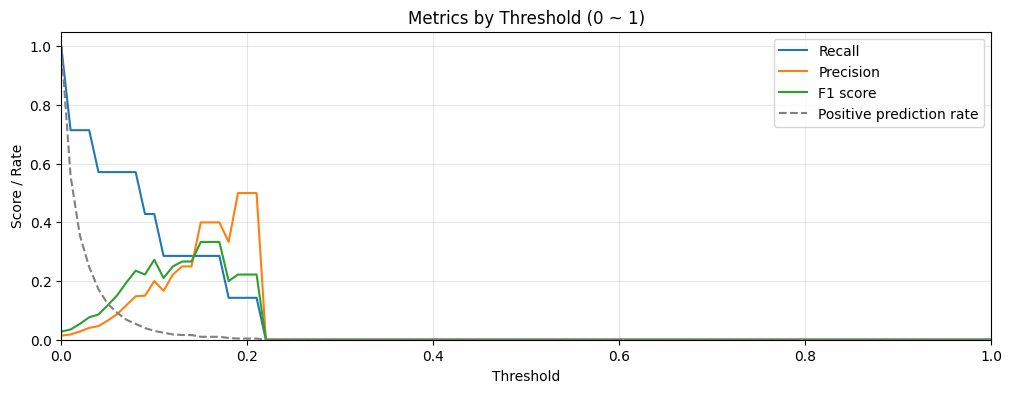

In [16]:
ts = np.linspace(0, 1, 101)
pred = proba[None, :] >= ts[:, None]          # (threshold 수, 샘플 수)

tp = (pred & (y_test == 1)).sum(1)
pp = pred.sum(1)                              # 양성으로 예측한 개수

recall = tp / y_test.sum()
precision = np.divide(tp, pp, out=np.zeros(len(ts)), where=pp > 0)
f1 = np.divide(2 * precision * recall, precision + recall,
               out=np.zeros(len(ts)), where=(precision + recall) > 0)
pos_rate = pp / len(proba)                    # 양성 판정 비율

plt.figure(figsize=(12, 4))
plt.plot(ts, recall, label='Recall')
plt.plot(ts, precision, label='Precision')
plt.plot(ts, f1, label='F1 score')
plt.plot(ts, pos_rate, ls='--', color='gray', label='Positive prediction rate')

plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.xlabel('Threshold')
plt.ylabel('Score / Rate')
plt.title('Metrics by Threshold (0 ~ 1)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### **모델에 weighted balance vs. SMOTE ?**
<img src="https://www.researchgate.net/profile/Rohitash-Chandra/publication/359191299/figure/fig2/AS:1168122144927744@1655513430375/SMOTE-processing-for-oversampling.png">

In [17]:
from imblearn.over_sampling import SMOTE

# 방법 1: class_weight='balanced'
model_bal = RandomForestClassifier(class_weight='balanced', random_state=42).fit(X_train, y_train)

# 방법 2: SMOTE (train 데이터에만 적용)
k = min(5, y_train.sum() - 1)
print(f"SMOTE k = {k}\n")
X_sm, y_sm = SMOTE(k_neighbors=k, random_state=42).fit_resample(X_train, y_train)
model_sm = RandomForestClassifier(random_state=42).fit(X_sm, y_sm)

# 비교 평가
for name, m in [('Baseline', model), ('Balanced weight', model_bal), ('SMOTE', model_sm)]:
    p = m.predict_proba(X_test)[:, 1]
    print(f"{name:16s} AUROC: {roc_auc_score(y_test, p):.4f} | AP: {average_precision_score(y_test, p):.4f}")

Baseline         AUROC: 0.7388 | AP: 0.1881
Balanced weight  AUROC: 0.7980 | AP: 0.1042
SMOTE            AUROC: 0.7473 | AP: 0.1140


In [20]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from imblearn.pipeline import Pipeline
from tqdm import tqdm

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
models = {
    'Baseline': RandomForestClassifier(random_state=42),
    'Balanced weight': RandomForestClassifier(class_weight='balanced', random_state=42),
    'SMOTE': Pipeline([('smote', SMOTE(k_neighbors=2, random_state=42)),
                       ('rf', RandomForestClassifier(random_state=42))]),
}
for name, m in tqdm(models.items()):
    s = cross_val_score(m, X, y, cv=cv, scoring='average_precision')
    print(f"{name:16s} AP: {s.mean():.4f} ± {s.std():.4f}")

 33%|███▎      | 1/3 [00:09<00:18,  9.04s/it]

Baseline         AP: 0.1402 ± 0.0984


 67%|██████▋   | 2/3 [00:22<00:11, 11.89s/it]

Balanced weight  AP: 0.1800 ± 0.1519


100%|██████████| 3/3 [00:51<00:00, 17.05s/it]

SMOTE            AP: 0.1188 ± 0.0725


**[imbalanced-learn](https://imbalanced-learn.org/stable/index.html)**

In [21]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE, BorderlineSMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler, TomekLinks, EditedNearestNeighbours, NearMiss
from imblearn.combine import SMOTETomek, SMOTEENN
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from tqdm import tqdm
import pandas as pd

rf = lambda **kw: RandomForestClassifier(random_state=42, **kw)
k = 2  # 소수 클래스가 적으니 작게

methods = {
    'Baseline':          rf(),
    'Class weight':      rf(class_weight='balanced'),
    # 오버샘플링
    'RandomOver':        Pipeline([('s', RandomOverSampler(random_state=42)), ('m', rf())]),
    'SMOTE':             Pipeline([('s', SMOTE(k_neighbors=k, random_state=42)), ('m', rf())]),
    'BorderlineSMOTE':   Pipeline([('s', BorderlineSMOTE(k_neighbors=k, m_neighbors=5, random_state=42)), ('m', rf())]),
    'ADASYN':            Pipeline([('s', ADASYN(n_neighbors=k, random_state=42)), ('m', rf())]),
    # 언더샘플링
    'RandomUnder':       Pipeline([('s', RandomUnderSampler(random_state=42)), ('m', rf())]),
    'TomekLinks':        Pipeline([('s', TomekLinks()), ('m', rf())]),
    'ENN':               Pipeline([('s', EditedNearestNeighbours()), ('m', rf())]),
    'NearMiss':          Pipeline([('s', NearMiss(version=1)), ('m', rf())]),
    # 하이브리드
    'SMOTETomek':        Pipeline([('s', SMOTETomek(smote=SMOTE(k_neighbors=k, random_state=42), random_state=42)), ('m', rf())]),
    'SMOTEENN':          Pipeline([('s', SMOTEENN(smote=SMOTE(k_neighbors=k, random_state=42), random_state=42)), ('m', rf())]),
    # 앙상블 내장 방식
    'BalancedRF':        BalancedRandomForestClassifier(random_state=42),
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
scoring = {'AUROC': 'roc_auc', 'AP': 'average_precision',
           'Recall': 'recall', 'Precision': 'precision', 'F1': 'f1'}

rows = []
for name, m in tqdm(methods.items()):
    r = cross_validate(m, X, y, cv=cv, scoring=scoring, n_jobs=-1, error_score=float('nan'))
    rows.append({'Method': name, **{k_: r[f'test_{k_}'].mean() for k_ in scoring}})

pd.DataFrame(rows).set_index('Method').round(4).sort_values('AP', ascending=False)

100%|██████████| 13/13 [02:33<00:00, 11.83s/it]


,AUROC,AP,Recall,Precision,F1
Method,,,,,
Class weight,0.7858,0.1800,0.0000,0.0000,0.0000
TomekLinks,0.7026,0.1760,0.0000,0.0000,0.0000
BalancedRF,0.7623,0.1690,0.5600,0.0860,0.1466
ENN,0.7125,0.1683,0.0000,0.0000,0.0000
RandomUnder,0.7218,0.1438,0.6800,0.0293,0.0561
SMOTEENN,0.7626,0.1413,0.0133,0.0200,0.0160
Baseline,0.6937,0.1402,0.0000,0.0000,0.0000
BorderlineSMOTE,0.6587,0.1272,0.0000,0.0000,0.0000
ADASYN,0.7468,0.1223,0.0000,0.0000,0.0000


In [22]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

# 1. 단일 분할: train에만 언더샘플링 적용, test는 원본 그대로 평가
X_rus, y_rus = RandomUnderSampler(random_state=42).fit_resample(X_train, y_train)
model_rus = RandomForestClassifier(random_state=42).fit(X_rus, y_rus)

p = model_rus.predict_proba(X_test)[:, 1]
print(f"[Test] AUROC: {roc_auc_score(y_test, p):.4f} | AP: {average_precision_score(y_test, p):.4f}")

# 2. 반복 교차검증 (결과의 신뢰도 확인용)
pipe = Pipeline([('rus', RandomUnderSampler(random_state=42)),
                 ('rf', RandomForestClassifier(random_state=42))])
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
r = cross_validate(pipe, X, y, cv=cv, scoring={'AUROC': 'roc_auc', 'AP': 'average_precision'}, n_jobs=-1)

for k_ in ['AUROC', 'AP']:
    s = r[f'test_{k_}']
    print(f"[CV]   {k_:5s}: {s.mean():.4f} ± {s.std():.4f}")

[Test] AUROC: 0.7701 | AP: 0.0583
[CV]   AUROC: 0.7288 ± 0.1447
[CV]   AP   : 0.1473 ± 0.1300


In [24]:
from sklearn.metrics import classification_report

pred = model_rus.predict(X_test)  # 기본 임계값 0.5 기준
print(classification_report(y_test, pred, target_names=['Negative (0)', 'Positive (1)']))

              precision    recall  f1-score   support

Negative (0)       1.00      0.74      0.85       493
Positive (1)       0.05      0.86      0.09         7

    accuracy                           0.74       500
   macro avg       0.52      0.80      0.47       500
weighted avg       0.98      0.74      0.84       500



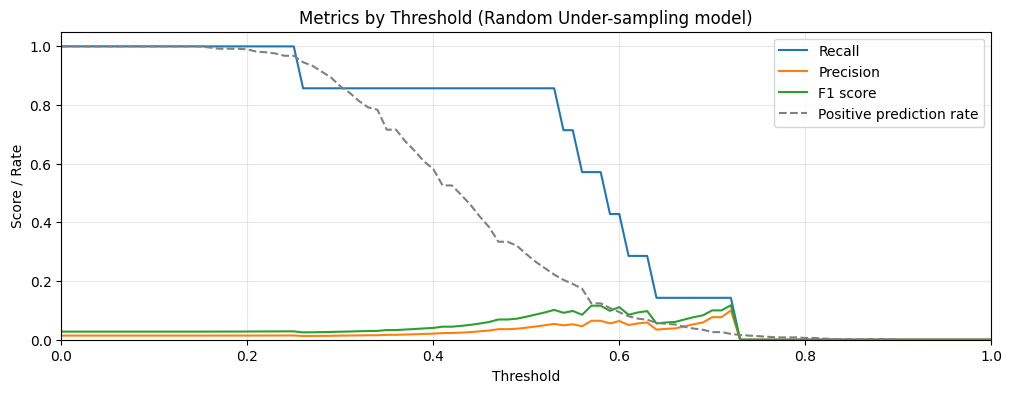

In [27]:
ts = np.linspace(0, 1, 101)
pred = p[None, :] >= ts[:, None]              # p: 언더샘플링 모델의 test 확률

tp = (pred & (y_test == 1)).sum(1)
pp = pred.sum(1)                              # 양성으로 예측한 개수

recall = tp / y_test.sum()
precision = np.divide(tp, pp, out=np.zeros(len(ts)), where=pp > 0)
f1 = np.divide(2 * precision * recall, precision + recall,
               out=np.zeros(len(ts)), where=(precision + recall) > 0)
pos_rate = pp / len(p)                        # 양성 판정 비율

plt.figure(figsize=(12, 4))
plt.plot(ts, recall, label='Recall')
plt.plot(ts, precision, label='Precision')
plt.plot(ts, f1, label='F1 score')
plt.plot(ts, pos_rate, ls='--', color='gray', label='Positive prediction rate')

plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.xlabel('Threshold')
plt.ylabel('Score / Rate')
plt.title('Metrics by Threshold (Random Under-sampling model)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()